# EDA

## Importing libtraries & Uploading Files

In [ ]:
# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

df = pd.read_excel("DecodeLabs Project 1.xlsx", sheet_name="Orders")

df.head()


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


## Basic Statistics

In [7]:
print(df.shape)
print(df.describe())
print(df.info())
print(df.duplicated().sum())

(1200, 14)
                      Date     Quantity    UnitPrice  ItemsInCart   TotalPrice
count                 1200  1200.000000  1200.000000  1200.000000  1200.000000
mean   2024-03-22 16:58:48     2.945833   356.412750     5.485000  1053.968300
min    2023-01-01 00:00:00     1.000000    11.390000     1.000000    11.390000
25%    2023-08-03 18:00:00     2.000000   186.062500     4.000000   410.520000
50%    2024-03-23 00:00:00     3.000000   364.210000     5.000000   823.615000
75%    2024-11-08 12:00:00     4.000000   521.570000     7.000000  1578.475000
max    2025-06-30 00:00:00     5.000000   699.930000    10.000000  3456.400000
std                    NaN     1.407557   197.177146     2.281983   819.856558
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          1200 non-null   object        
 1   Date   

## Descriptive Statistics

In [12]:
numeric_cols = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]

df[numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
Quantity,1200.0,2.945833,1.407557,1.00,2.0000,3.000,4.000,5.00
UnitPrice,1200.0,356.412750,197.177146,11.39,186.0625,364.210,521.570,699.93
ItemsInCart,1200.0,5.485000,2.281983,1.00,4.0000,5.000,7.000,10.00
TotalPrice,1200.0,1053.968300,819.856558,11.39,410.5200,823.615,1578.475,3456.40


In [13]:
df[numeric_cols].median()

Quantity         3.000
UnitPrice      364.210
ItemsInCart      5.000
TotalPrice     823.615
dtype: float64

## Categorical Analysis

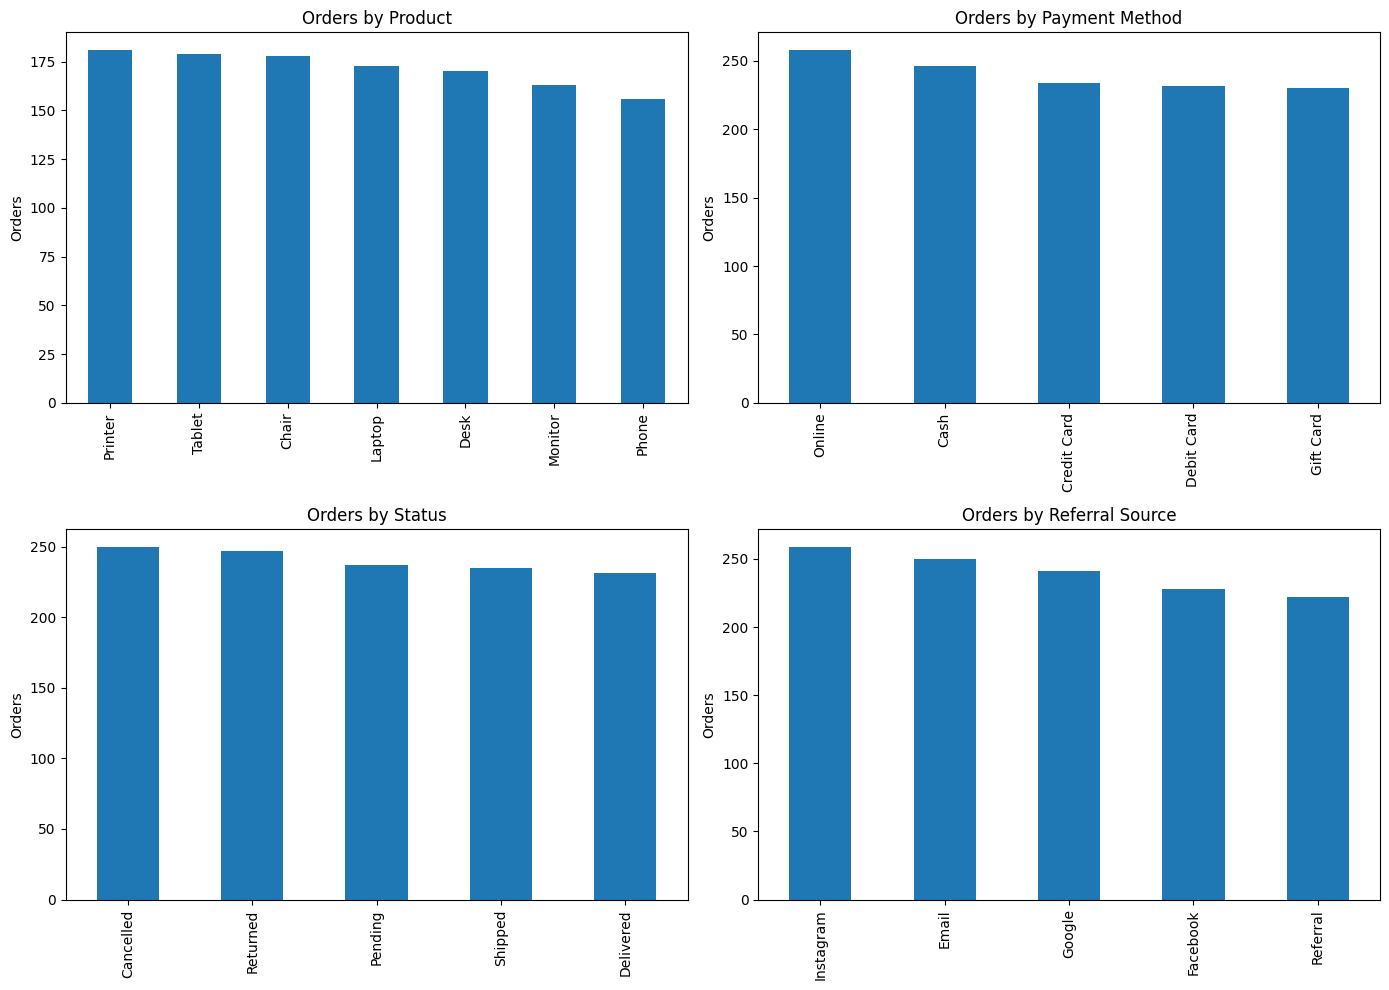

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

df["Product"].value_counts().plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Orders by Product")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Orders")

df["PaymentMethod"].value_counts().plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Orders by Payment Method")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Orders")

df["OrderStatus"].value_counts().plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Orders by Status")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Orders")

df["ReferralSource"].value_counts().plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Orders by Referral Source")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Orders")

plt.tight_layout()
plt.show()

## Numerical Distributions

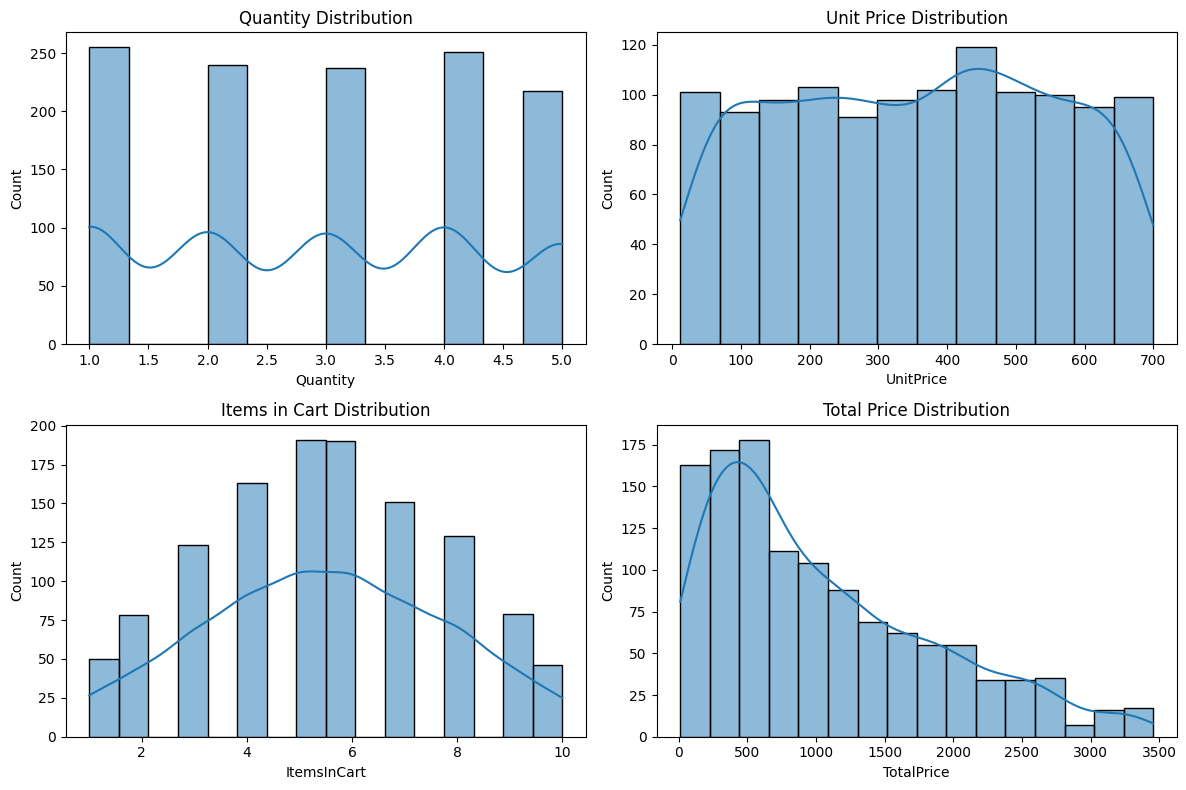

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["Quantity"], kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Quantity Distribution")

sns.histplot(df["UnitPrice"], kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Unit Price Distribution")

sns.histplot(df["ItemsInCart"], kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Items in Cart Distribution")

sns.histplot(df["TotalPrice"], kde=True, ax=axes[1, 1])
axes[1, 1].set_title("Total Price Distribution")

plt.tight_layout()
plt.show()

## Outlier Analysis

In [19]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(col, ":", len(outliers), "outliers")

Quantity : 0 outliers
UnitPrice : 0 outliers
ItemsInCart : 0 outliers
TotalPrice : 8 outliers


## Time Analysis

In [21]:
df["Year"] = df["Date"].dt.year
yearly_orders = df.groupby("Year").size()

yearly_orders
yearly_revenue = df.groupby("Year")["TotalPrice"].sum()

yearly_revenue

Year
2023    552643.24
2024    480235.87
2025    231882.85
Name: TotalPrice, dtype: float64

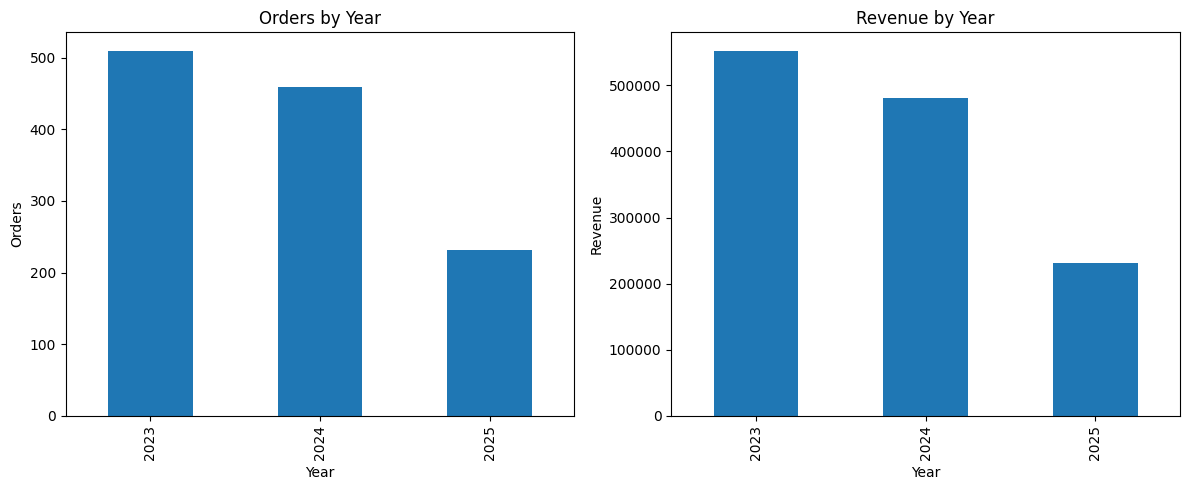

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

yearly_orders.plot(kind="bar", ax=axes[0])
axes[0].set_title("Orders by Year")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Orders")

yearly_revenue.plot(kind="bar", ax=axes[1])
axes[1].set_title("Revenue by Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Revenue")

plt.tight_layout()
plt.show()

## Product & Revenue Analysis

In [23]:
product_analysis = df.groupby("Product").agg(
    Orders=("OrderID", "count"),
    Quantity=("Quantity", "sum"),
    Revenue=("TotalPrice", "sum"),
    AverageOrderValue=("TotalPrice", "mean")
).sort_values("Revenue", ascending=False)

product_analysis

,Orders,Quantity,Revenue,AverageOrderValue
Product,,,,
Chair,178,562,195620.11,1098.989382
Printer,181,542,195612.61,1080.732652
Laptop,173,535,192126.56,1110.558150
Tablet,179,497,186568.95,1042.284637
Monitor,163,480,175651.41,1077.616012
Desk,170,508,167459.93,985.058412
Phone,156,411,151722.39,972.579423


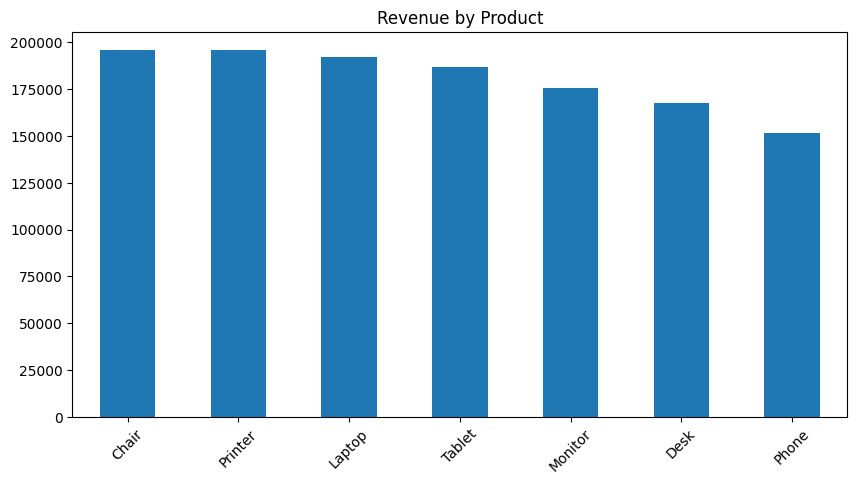

In [25]:
product_analysis["Revenue"].plot(kind="bar", figsize=(10, 5))

plt.title("Revenue by Product")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=45)
plt.show()

## Correlation Analysis

In [26]:
correlation = df[numeric_cols].corr()

correlation

,Quantity,UnitPrice,ItemsInCart,TotalPrice
Quantity,1.000000,0.014553,0.650061,0.615251
UnitPrice,0.014553,1.000000,0.000602,0.717081
ItemsInCart,0.650061,0.000602,1.000000,0.392540
TotalPrice,0.615251,0.717081,0.392540,1.000000


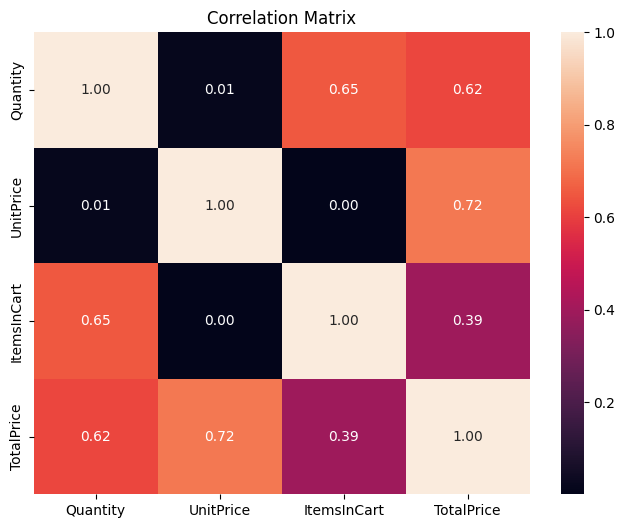

In [27]:
plt.figure(figsize=(8, 6))

sns.heatmap(correlation, annot=True, fmt=".2f")

plt.title("Correlation Matrix")
plt.show()

## Key Questions & Findings

In [31]:
total_revenue = df["TotalPrice"].sum()
total_orders = df["OrderID"].nunique()
top_product = product_analysis["Revenue"].idxmax()
most_common_payment_method = df["PaymentMethod"].mode()[0]

print("Total Revenue: $", total_revenue)
print("Total Orders: ", total_orders)
print("Top Product: ", top_product)
print("Most Common Payment Method: ", most_common_payment_method)

Total Revenue: $ 1264761.96
Total Orders:  1200
Top Product:  Chair
Most Common Payment Method:  Online


## Conclusion

The exploratory analysis provided an overview of the e-commerce dataset and identified important patterns in orders, products, revenue, payment methods, referral sources, and time-based performance.

The analysis also examined numerical distributions, potential outliers, and relationships between numerical variables.

These findings can be used as a foundation for the next stage of business analysis and dashboard development.